# San Luis Valley: from HyP3 interferograms to displacement at the wells (steps 1.7 to 1.9)

Run top to bottom. Native Windows, no MintPy: it needs only `numpy`, `pandas`, `scipy`, `rasterio` and `matplotlib`.

**What it does**
1. Indexes every unwrapped interferogram you downloaded (`hyp3_test` and `hyp3_full`).
2. Reads the phase at each well pixel and at a reference pixel (by longitude/latitude, so it does not matter that HyP3 clips each pair to a slightly different extent).
3. Subtracts the reference, drops pairs that are not trustworthy at that pixel, and inverts the pair network into a displacement time series at each well.
4. Compares each series with that well's own water level, fits a seasonal cycle, and tests whether the signal looks like the aquifer instead of the atmosphere.

**What it does not do (compared with MintPy):** no deramping, no tropospheric correction, no automatic unwrapping-error correction. It checks the residual of the network inversion instead. Treat the numbers as an upper bound on noise, and say so in the report.

**Inputs it expects** (all made by earlier notebooks):
- `C:/insar/wells_scored.csv` from the cell that joined coherence, swing and depth class (columns `name, lon, lat, swing_m, tier, n_dates, depth_class`)
- `C:/insar/well_obs.csv` from the wells notebook
- products in `C:/insar/hyp3_test` and `C:/insar/hyp3_full`

In [1]:
import re, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import rasterio
from rasterio.transform import rowcol
from rasterio.warp import transform
from scipy import sparse, stats
from scipy.sparse.csgraph import connected_components
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=DeprecationWarning)

DATA_DIR = Path("C:/insar")
WELLS_CSV = DATA_DIR / "wells_scored.csv"
OBS_CSV = DATA_DIR / "well_obs.csv"
ZONE_CSV = None            # optional CSV with columns name, zone (e.g. "south"/"north" of the Rio Grande), made in QGIS

# Reference pixel candidates (lon, lat). The first is used for the main results; add others to test sensitivity.
REFS = {"A": (-105.9078, 38.0065)}

SIGN = -1                  # GAMMA unwrapped phase: positive = range increase = away from satellite. -1 gives uplift-positive.
WAVELENGTH_M = 0.0555      # Sentinel-1
COS_INC = 0.8              # LOS = vertical * cos(incidence); rough, used only to convert slopes to vertical
CORR_MIN = 0.3             # drop a pair at a pixel if coherence there is below this
HALF, REF_HALF = 1, 3      # pixel window half-widths: 3x3 at wells (240 m), 7x7 at the reference (560 m)
MAX_INTERP_GAP_DAYS = 100  # do not interpolate water levels across a gap longer than this
MIN_EPOCHS = 8             # need at least this many dates to fit anything

## Optional: download the full-network products

Set `DOWNLOAD = True` only if the products are not on disk yet. It asks for your Earthdata bearer token.

In [2]:
DOWNLOAD = False
if DOWNLOAD:
    import hyp3_sdk
    from collections import Counter
    hyp3 = hyp3_sdk.HyP3(prompt="token")
    jobs = hyp3.find_jobs(name="slv_full")
    print(len(jobs), "jobs:", dict(Counter(j.status_code for j in jobs)))
    ok = jobs.filter_jobs(succeeded=True, pending=False, running=False, failed=False, include_expired=False)
    for f in ok.download_files(DATA_DIR / "hyp3_full"):
        hyp3_sdk.util.extract_zipped_product(f)

## Index the products

In [3]:
rows = []
for folder in ("hyp3_test", "hyp3_full"):
    for tif in sorted((DATA_DIR / folder).rglob("*_unw_phase.tif")):
        m = re.search(r"_(\d{8})T\d{6}_(\d{8})T", tif.name)
        rows.append({"ref": pd.Timestamp(m.group(1)), "sec": pd.Timestamp(m.group(2)), "path": tif})
prods = pd.DataFrame(rows).drop_duplicates(["ref", "sec"]).sort_values(["ref", "sec"]).reset_index(drop=True)
dates = sorted(set(prods.ref) | set(prods.sec))
print(len(prods), "interferograms |", len(dates), "dates |", dates[0].date(), "to", dates[-1].date())
print("temporal baselines (days):", (prods.sec - prods.ref).dt.days.value_counts().sort_index().to_dict())

120 interferograms | 42 dates | 2022-07-30 to 2023-12-28
temporal baselines (days): {12: 39, 24: 38, 36: 38, 48: 5}


## Read the phase at the wells and the reference

One pass over the products. Each pixel value is the median of a small window (3x3 at wells, 7x7 at the reference). We also keep the coherence and the unwrapping connected-component label, because phase from two different components cannot be compared.

In [4]:
wells = pd.read_csv(WELLS_CSV)
wells = wells[(wells.n_dates >= 18) | (wells.tier == "daily")].dropna(subset=["lon", "lat"]).reset_index(drop=True)
refs = pd.DataFrame([{"name": f"REF_{k}", "lon": v[0], "lat": v[1]} for k, v in REFS.items()])
pts = pd.concat([wells[["name", "lon", "lat"]], refs], ignore_index=True)
half = np.r_[np.full(len(wells), HALF), np.full(len(refs), REF_HALF)]
print(len(wells), "wells +", len(refs), "reference pixel(s)")


def win_median(a, valid, r, c, h):
    r0, r1, c0, c1 = r - h, r + h + 1, c - h, c + h + 1
    if r0 < 0 or c0 < 0 or r1 > a.shape[0] or c1 > a.shape[1]:
        return np.nan
    ok = valid[r0:r1, c0:c1]
    return float(np.median(a[r0:r1, c0:c1][ok])) if ok.sum() >= 0.5 * ok.size else np.nan


PH = np.full((len(prods), len(pts)), np.nan)
CO = PH.copy()
CC = np.zeros(PH.shape, dtype=int)
n_no_cc = 0
for i, p in enumerate(prods.itertuples()):
    tif = p.path
    cc_path = tif.with_name(tif.name.replace("_unw_phase", "_conncomp"))
    with rasterio.open(tif) as s1, rasterio.open(tif.with_name(tif.name.replace("_unw_phase", "_corr"))) as s2:
        ph, co = s1.read(1).astype("float64"), s2.read(1).astype("float64")
        if cc_path.exists():
            with rasterio.open(cc_path) as s3:
                cc = s3.read(1)
        else:
            cc = np.ones(ph.shape, dtype="uint8")
            n_no_cc += 1
        xs, ys = transform("EPSG:4326", s1.crs, pts.lon.tolist(), pts.lat.tolist())
        rr, cl = rowcol(s1.transform, xs, ys)
    vph, vco = np.isfinite(ph) & (ph != 0), np.isfinite(co) & (co > 0)
    for j, (r, c) in enumerate(zip(rr, cl)):
        PH[i, j] = win_median(ph, vph, r, c, half[j])
        CO[i, j] = win_median(co, vco, r, c, half[j])
        if 0 <= r < cc.shape[0] and 0 <= c < cc.shape[1]:
            CC[i, j] = cc[r, c]
print("fraction of (pair, well) samples with a valid phase:", round(float(np.isfinite(PH[:, :len(wells)]).mean()), 2))
if n_no_cc:
    print(f"NOTE: no connected-component layer for {n_no_cc} of {len(prods)} pairs, so unwrapping-region mismatches are not screened here. See the closure check below.")

91 wells + 1 reference pixel(s)
fraction of (pair, well) samples with a valid phase: 1.0
NOTE: no connected-component layer for 120 of 120 pairs, so unwrapping-region mismatches are not screened here. See the closure check below.


## Closure check (substitute for the missing connected-component layer)

For any three dates a < b < c with all three pairs present, the phase from a to b plus b to c must equal a to c. After subtracting the reference, a closure far from zero at a well means an unwrapping jump (a multiple of 2 pi, about 28 mm of apparent motion) in one of the three pairs. This only diagnoses; it does not drop anything. Wells with many bad triplets, or a large `rms_mm` later, should not be trusted.

In [5]:
rj0 = len(wells)
D = PH[:, :len(wells)] - PH[:, [rj0]]
by_ref = {}
for k, (r, s_) in enumerate(zip(prods.ref, prods.sec)):
    by_ref.setdefault(r, {})[s_] = k
trip = np.array([(k12, k23, d1[t]) for r, d1 in by_ref.items() for s_, k12 in d1.items()
                 for t, k23 in by_ref.get(s_, {}).items() if t in d1])
clos = D[trip[:, 0]] + D[trip[:, 1]] - D[trip[:, 2]]
bad = (np.abs(clos) > 3.0)                         # radians; an unwrapping jump is about 6.3
frac_bad = np.nanmean(np.where(np.isfinite(clos), bad, np.nan), axis=0)
closure = pd.DataFrame({"name": wells["name"], "frac_bad_triplets": frac_bad.round(3)})
print(len(trip), "triplets | wells with more than 5% bad triplets:", int((frac_bad > 0.05).sum()), "of", len(wells))
print("median |closure| (mm):", round(float(np.nanmedian(np.abs(clos)) * WAVELENGTH_M / (4 * np.pi) * 1000), 2))
closure.sort_values("frac_bad_triplets", ascending=False).head(8)

118 triplets | wells with more than 5% bad triplets: 0 of 91
median |closure| (mm): 0.32


,name,frac_bad_triplets
0,DWR:11145,0.0
1,DWR:11217,0.0
2,DWR:152100,0.0
3,DWR:153001,0.0
4,DWR:153002,0.0
5,DWR:153003,0.0
6,DWR:153004,0.0
7,DWR:31482,0.0


## Invert the network to a displacement time series

For each well and each reference: subtract the reference phase in every pair, keep pairs where both pixels are in the same unwrapped component with coherence of at least `CORR_MIN`, convert to millimetres of line-of-sight displacement (uplift positive), and solve for the displacement at each date by least squares. The first date is zero.

`rms_mm` is the residual of that fit. Large values mean the pairs disagree with each other (unwrapping errors or noise).

In [6]:
ia = prods.ref.map({d: k for k, d in enumerate(dates)}).to_numpy()
ib = prods.sec.map({d: k for k, d in enumerate(dates)}).to_numpy()
K_MM = SIGN * WAVELENGTH_M / (4 * np.pi) * 1000   # mm of uplift-positive LOS displacement per radian


def invert(j, rj):
    ok = (np.isfinite(PH[:, j]) & np.isfinite(PH[:, rj]) & (CC[:, j] > 0) & (CC[:, j] == CC[:, rj]) & (CO[:, j] >= CORR_MIN))
    out = np.full(len(dates), np.nan)
    if ok.sum() < 3:
        return out, np.nan, int(ok.sum())
    a, b, d = ia[ok], ib[ok], K_MM * (PH[ok, j] - PH[ok, rj])
    g = sparse.coo_matrix((np.ones(len(a)), (a, b)), shape=(len(dates), len(dates)))
    _, lab = connected_components(g, directed=False)
    big = np.bincount(lab[np.r_[a, b]]).argmax()
    keep = lab[a] == big
    a, b, d = a[keep], b[keep], d[keep]
    nodes = np.unique(np.r_[a, b])
    col = {n: k for k, n in enumerate(nodes[1:])}
    A = np.zeros((len(a), len(nodes) - 1))
    for k, (x, y) in enumerate(zip(a, b)):
        if x in col:
            A[k, col[x]] = -1
        if y in col:
            A[k, col[y]] = 1
    sol, *_ = np.linalg.lstsq(A, d, rcond=None)
    out[nodes[0]] = 0
    out[nodes[1:]] = sol
    return out, float(np.sqrt(np.mean((A @ sol - d) ** 2))), len(a)


DISP, RMS, NPAIR = {}, {}, {}
for k, v in REFS.items():
    rj = len(wells) + list(REFS).index(k)
    res_ = [invert(j, rj) for j in range(len(wells))]
    DISP[k] = np.array([r[0] for r in res_])
    RMS[k] = np.array([r[1] for r in res_])
    NPAIR[k] = np.array([r[2] for r in res_])
main = list(REFS)[0]
print("reference", main, "| wells with a series:", int(np.isfinite(DISP[main]).any(axis=1).sum()), "of", len(wells))
print("inversion residual rms (mm), median / 90th percentile:", np.nanmedian(RMS[main]).round(2), np.nanpercentile(RMS[main], 90).round(2))

reference A | wells with a series: 91 of 91
inversion residual rms (mm), median / 90th percentile: 0.3 0.57


## Compare with each well's own water level

Head is minus depth to water, in metres, linearly interpolated to the InSAR dates only where the two nearest observations are no more than `MAX_INTERP_GAP_DAYS` apart. The slope of displacement against head is an effective storage coefficient: `Sk = slope / COS_INC / 1000` (vertical, dimensionless). The seasonal fit is displacement = constant + trend + annual sine and cosine; `amp_mm` is the annual amplitude.

The standard errors assume independent errors, which is optimistic for 20 monthly points and for atmosphere.

In [7]:
obs = pd.read_csv(OBS_CSV)
obs["name"] = obs.source + ":" + obs.id.astype(str)
obs["t"] = pd.to_datetime(obs.time, utc=True, format="mixed").dt.tz_localize(None).dt.normalize()
obs = obs.groupby(["name", "t"], as_index=False).depth_ft.mean()

epochs = np.array(dates, dtype="datetime64[D]")
tday = (epochs - epochs[0]).astype(float)
om = 2 * np.pi / 365.25
X = np.c_[np.ones(len(tday)), tday, np.sin(om * tday), np.cos(om * tday)]


def head_at(name):
    s = obs[obs.name == name].sort_values("t")
    if s.empty:
        return np.full(len(epochs), np.nan)
    t = s.t.to_numpy().astype("datetime64[D]").astype(float)
    e = epochs.astype(float)
    y = np.interp(e, t, -s.depth_ft.to_numpy() * 0.3048, left=np.nan, right=np.nan)
    k = np.searchsorted(t, e, side="right")
    inside = (k > 0) & (k < len(t))
    gap = np.where(inside, t[np.clip(k, 0, len(t) - 1)] - t[np.clip(k - 1, 0, len(t) - 1)], np.inf)
    y[gap > MAX_INTERP_GAP_DAYS] = np.nan
    return y


def seasonal(y):
    v = np.isfinite(y)
    if v.sum() < MIN_EPOCHS:
        return np.nan, np.nan
    Xv = X[v]
    beta, *_ = np.linalg.lstsq(Xv, y[v], rcond=None)
    r_ = y[v] - Xv @ beta
    cov = (r_ @ r_ / max(v.sum() - 4, 1)) * np.linalg.pinv(Xv.T @ Xv)
    s, c = beta[2], beta[3]
    amp = float(np.hypot(s, c))
    gvec = np.array([s, c]) / amp
    return amp, float(np.sqrt(gvec @ cov[2:, 2:] @ gvec))


rows = []
for i, wr in wells.iterrows():
    y, h = DISP[main][i], head_at(wr["name"])
    v = np.isfinite(y) & np.isfinite(h)
    row = {"name": wr["name"], "depth_class": wr.get("depth_class"), "swing_m": wr.get("swing_m"), "lon": wr.lon, "lat": wr.lat,
           "n_dates": int(np.isfinite(y).sum()), "n_pairs": NPAIR[main][i], "rms_mm": RMS[main][i], "n_head": int(v.sum())}
    row["amp_mm"], row["amp_se"] = seasonal(y)
    if v.sum() >= MIN_EPOCHS and np.ptp(h[v]) > 0:
        lr = stats.linregress(h[v], y[v])
        row.update(slope_mm_per_m=lr.slope, slope_se=lr.stderr, r=lr.rvalue, sk_eff=lr.slope / COS_INC / 1000)
    for k in REFS:
        row[f"amp_{k}"] = seasonal(DISP[k][i])[0]
    rows.append(row)
res = pd.DataFrame(rows)
if ZONE_CSV:
    res = res.merge(pd.read_csv(ZONE_CSV), on="name", how="left")
res.to_csv(DATA_DIR / "well_results.csv", index=False)
print("saved", DATA_DIR / "well_results.csv")
res.sort_values("swing_m", ascending=False).head(12).round(3)

saved C:\insar\well_results.csv


,name,depth_class,swing_m,lon,lat,n_dates,n_pairs,rms_mm,n_head,amp_mm,amp_se,slope_mm_per_m,slope_se,r,sk_eff,amp_A
8,DWR:31512,deep (likely confined),14.149,-106.003,37.401,42,120,0.525,41,20.756,3.173,2.750,0.490,0.668,0.003,20.756
13,DWR:31576,deep (likely confined),12.829,-106.012,37.418,42,117,0.522,41,20.405,3.020,3.214,0.602,0.650,0.004,20.405
18,DWR:31695,deep (likely confined),8.233,-105.855,37.630,42,120,0.351,29,6.307,2.085,0.897,0.716,0.235,0.001,6.307
7,DWR:31482,deep (likely confined),7.084,-106.038,37.285,42,120,0.808,41,8.436,3.199,0.883,1.067,0.131,0.001,8.436
9,DWR:31519,deep (likely confined),5.377,-105.764,37.431,42,110,0.936,41,9.535,2.882,1.399,1.462,0.151,0.002,9.535
58,DWR:6073,shallow (likely unconfined),4.612,-106.149,37.749,42,120,0.262,39,2.936,2.021,0.170,1.074,0.026,0.000,2.936
34,DWR:5740,unknown,4.590,-105.734,37.371,42,119,0.309,41,7.759,2.844,-2.668,1.786,-0.233,-0.003,7.759
67,DWR:6359,unknown,4.529,-105.969,37.497,42,120,0.365,39,9.086,2.823,3.247,1.708,0.298,0.004,9.086
46,DWR:5830,deep (likely confined),4.395,-106.077,38.013,42,120,0.358,41,3.819,1.678,1.710,0.955,0.276,0.002,3.819
51,DWR:5935,deep (likely confined),4.328,-105.837,37.296,42,118,0.834,41,7.569,3.457,1.447,1.800,0.128,0.002,7.569


## Is it the aquifer or the atmosphere?

Three checks that use only the data you have:
1. **Spatial contrast:** deep (likely confined) wells should show larger seasonal amplitude than shallow ones, which the atmosphere affects equally.
2. **Dose-response:** among deep wells, amplitude should rise with the well's own head swing.
3. **Sign:** where the aquifer is driving the ground, slope against head should be positive (head up, ground up). If most deep wells are negative, either `SIGN` is wrong or the atmosphere dominates.

A well counts as "detected" below if its amplitude is more than twice its standard error. That is the SNR-2 rule from the plan, with the optimistic error caveat above.

In [8]:
res["detected"] = res.amp_mm > 2 * res.amp_se
by = res.groupby(res.depth_class.fillna("unknown")).agg(
    wells=("name", "size"), with_series=("amp_mm", lambda s: int(s.notna().sum())),
    median_amp_mm=("amp_mm", "median"), median_se_mm=("amp_se", "median"), detected=("detected", "sum"),
    median_rms_mm=("rms_mm", "median"))
print(by.round(2).to_string())

deep = res[res.depth_class.fillna("").str.startswith("deep")].dropna(subset=["amp_mm"])
if len(deep) >= 4:
    rho = stats.spearmanr(deep.swing_m, deep.amp_mm)
    print(f"\nDose-response, deep wells: Spearman rho(amplitude, head swing) = {rho.statistic:.2f} (p = {rho.pvalue:.2f}, n = {len(deep)})")
big = deep[(deep.swing_m >= 3) & deep.r.notna()]
if len(big):
    print(f"Sign check, deep wells with swing >= 3 m: median r = {big.r.median():.2f}, {int((big.r > 0).sum())} of {len(big)} positive")
    print("Median effective Sk (vertical):", f"{big.sk_eff.median():.1e}")
if len(REFS) > 1:
    cols = [f"amp_{k}" for k in REFS]
    print("\nReference sensitivity at the 8 deep wells with the largest swing:")
    print(deep.sort_values("swing_m", ascending=False).head(8)[["name", "swing_m"] + cols].round(2).to_string(index=False))

                             wells  with_series  median_amp_mm  median_se_mm  detected  median_rms_mm
depth_class                                                                                          
deep (likely confined)          31           31           5.74          2.02        17           0.36
shallow (likely unconfined)     56           56           6.00          2.22        40           0.28
unknown                          4            4           9.33          2.54         4           0.30

Dose-response, deep wells: Spearman rho(amplitude, head swing) = 0.22 (p = 0.24, n = 31)
Sign check, deep wells with swing >= 3 m: median r = 0.14, 10 of 10 positive
Median effective Sk (vertical): 1.8e-03


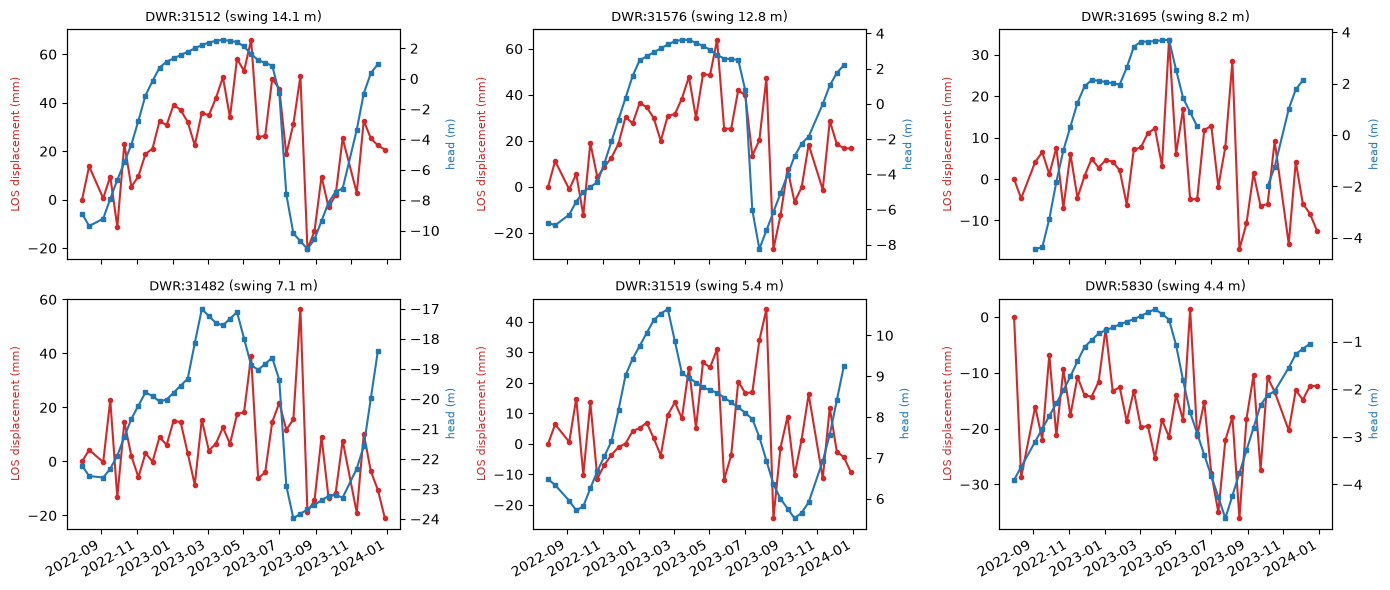

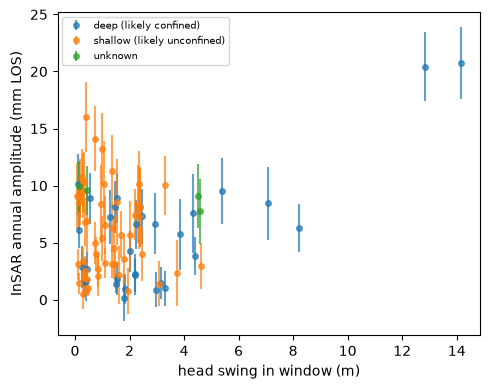

In [9]:
top = deep.sort_values("swing_m", ascending=False).head(6)
fig, axes = plt.subplots(2, 3, figsize=(14, 6), sharex=True)
for ax, (_, wr) in zip(axes.ravel(), top.iterrows()):
    i = int(wells.index[wells.name == wr["name"]][0])
    ax.plot(epochs, DISP[main][i], "o-", ms=3, color="tab:red")
    ax.set_title(f"{wr['name']} (swing {wr['swing_m']:.1f} m)", fontsize=9)
    ax.set_ylabel("LOS displacement (mm)", color="tab:red", fontsize=8)
    ax2 = ax.twinx()
    ax2.plot(epochs, head_at(wr["name"]), "s-", ms=3, color="tab:blue")
    ax2.set_ylabel("head (m)", color="tab:blue", fontsize=8)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

plt.figure(figsize=(5, 4))
for cls, g in res.dropna(subset=["amp_mm"]).groupby(res.depth_class.fillna("unknown")):
    plt.errorbar(g.swing_m, g.amp_mm, yerr=g.amp_se, fmt="o", ms=4, label=cls, alpha=0.7)
plt.xlabel("head swing in window (m)"); plt.ylabel("InSAR annual amplitude (mm LOS)"); plt.legend(fontsize=7)
plt.tight_layout(); plt.show()

In [10]:
lon_, lat_ = wells.lon.to_numpy(), wells.lat.to_numpy()
G = np.c_[np.ones(len(wells)), (lon_ - lon_.mean()) * 87.7, (lat_ - lat_.mean()) * 111]
D3 = DISP[main].copy()
for t in range(D3.shape[1]):
    v = np.isfinite(D3[:, t])
    if v.sum() > 10:
        coef, *_ = np.linalg.lstsq(G[v], D3[v, t], rcond=None)
        D3[:, t] -= G @ coef
res["amp_plane"] = [seasonal(D3[i])[0] for i in range(len(wells))]
res["dist_ref_km"] = np.hypot((res.lon - REFS[main][0]) * 87.7, (res.lat - REFS[main][1]) * 111)
res["dist_bin"] = pd.cut(res.dist_ref_km, [0, 15, 30, 50, 100])
print(res.groupby("dist_bin", observed=True)[["amp_mm", "amp_plane"]].median().round(1))
print(res.sort_values("amp_plane", ascending=False).head(10)[["name", "depth_class", "swing_m", "amp_mm", "amp_plane"]].round(1).to_string(index=False))

           amp_mm  amp_plane
dist_bin                    
(0, 15]       1.9        1.6
(15, 30]      2.1        1.4
(30, 50]      6.3        2.4
(50, 100]     9.1        2.6
      name                 depth_class  swing_m  amp_mm  amp_plane
 DWR:31512      deep (likely confined)     14.1    20.8       16.7
 DWR:31576      deep (likely confined)     12.8    20.4       16.6
  DWR:6414 shallow (likely unconfined)      0.4    16.0       11.1
  DWR:5958 shallow (likely unconfined)      0.7    14.1        7.7
  DWR:6394 shallow (likely unconfined)      1.0    13.2        6.8
DWR:153004 shallow (likely unconfined)      2.4     8.1        5.2
DWR:153003 shallow (likely unconfined)      2.4     8.1        5.1
DWR:152100 shallow (likely unconfined)      3.8     2.3        4.7
DWR:153001 shallow (likely unconfined)      2.3     8.4        4.5
DWR:153002 shallow (likely unconfined)      0.9     8.4        4.5


In [11]:
c = res[res.name == "DWR:31512"].iloc[0]
res["d_pair_km"] = np.hypot((res.lon - c.lon) * 87.7, (res.lat - c.lat) * 111)
far = res[res.d_pair_km > 25]
print("null (wells >25 km from the pair): median", round(far.amp_plane.median(), 1), "| 95th pct", round(far.amp_plane.quantile(.95), 1), "| n", len(far))
near = res[res.d_pair_km <= 25].sort_values("d_pair_km")
print(near[["name", "d_pair_km", "swing_m", "amp_plane"]].round(1).to_string(index=False))

null (wells >25 km from the pair): median 1.6 | 95th pct 3.8 | n 57
      name  d_pair_km  swing_m  amp_plane
 DWR:31512        0.0     14.1       16.7
 DWR:31576        2.1     12.8       16.6
  DWR:6414        3.3      0.4       11.1
  DWR:5958        6.8      0.7        7.7
  DWR:6394        9.9      1.0        6.8
  DWR:6487       10.6      0.4        0.3
  DWR:6359       11.1      4.5        2.2
  DWR:5954       11.5      0.3        3.0
  DWR:6447       11.6      0.2        1.0
 DWR:31482       13.2      7.1        1.3
  DWR:5933       13.9      1.4        2.0
  DWR:6286       14.7      3.9        2.4
 DWR:31545       16.0      2.3        1.5
 DWR:31612       16.1      2.9        2.5
 DWR:11217       16.1      2.0        3.1
DWR:153002       18.1      0.9        4.5
DWR:153001       18.1      2.3        4.5
DWR:153003       18.2      2.4        5.1
DWR:153004       18.2      2.4        5.2
  DWR:5945       18.7      1.5        2.0
  DWR:5935       18.7      4.3        3.9
  DWR:63

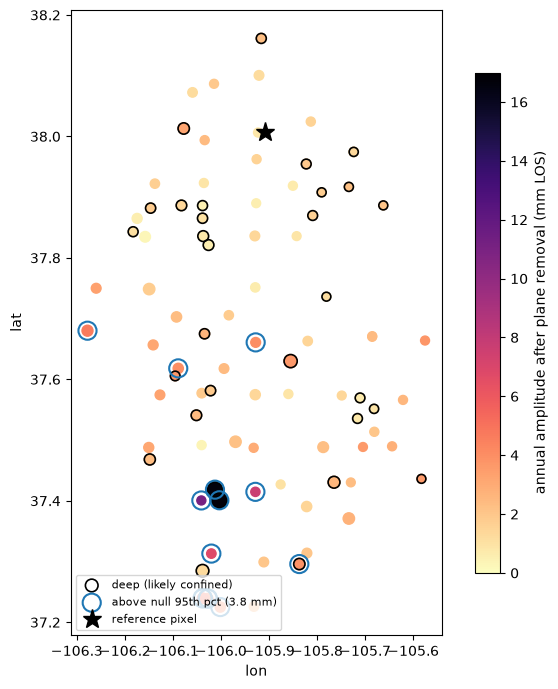

In [12]:
thr = far.amp_plane.quantile(.95)
fig, ax = plt.subplots(figsize=(7, 7))
sc = ax.scatter(res.lon, res.lat, c=res.amp_plane, s=40 + 6 * res.swing_m, cmap="magma_r", vmin=0, vmax=17)
deep = res.depth_class.fillna("").str.startswith("deep")
ax.scatter(res.lon[deep], res.lat[deep], s=40 + 6 * res.swing_m[deep], facecolor="none", edgecolor="k", lw=1.2, label="deep (likely confined)")
hit = res.amp_plane > thr
ax.scatter(res.lon[hit], res.lat[hit], s=170, facecolor="none", edgecolor="tab:blue", lw=1.5, label=f"above null 95th pct ({thr:.1f} mm)")
ax.plot(*REFS[main], "k*", ms=14, label="reference pixel")
ax.set_aspect(1 / np.cos(np.radians(37.7)))
plt.colorbar(sc, label="annual amplitude after plane removal (mm LOS)", shrink=0.8)
ax.set_xlabel("lon"); ax.set_ylabel("lat"); ax.legend(fontsize=8, loc="lower left")
plt.tight_layout(); plt.show()
res.to_csv(DATA_DIR / "well_results_plane.csv", index=False)

In [13]:
np.savez_compressed(DATA_DIR / "extracted.npz", PH=PH, CO=CO, CC=CC, ref=prods.ref.to_numpy(), sec=prods.sec.to_numpy(),
                    name=pts.name.to_numpy().astype(str), lon=pts.lon.to_numpy(), lat=pts.lat.to_numpy())
pd.DataFrame(D3.T, index=pd.to_datetime(epochs), columns=wells.name).rename_axis("date").to_csv(DATA_DIR / "well_timeseries_plane_mm.csv")